# SSI under extreme measurement noise

How far can stochastic subspace identification go when the sensors are
bad? This notebook drives the three-mass chain of notebooks 05 and 06
with random forces, measures the velocities of all three masses and adds
white measurement noise of up to **30 times** the standard deviation of
the signal (a signal-to-noise ratio of −30 dB). It covers

1. what such data look like,
2. why SSI can still work: white noise only touches the correlation at
   lag zero,
3. an identification at −20 dB,
4. how the error grows with the noise, and how much data that costs,
5. what helps (record length, decimation, channels) and what hurts
   (band-pass filtering).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, decimate, butter, sosfiltfilt

from pyharminv import (output_correlation, random_vibration, ssi_cov, ssi_data,
                       ssi_stabilization)

plt.rcParams["figure.figsize"] = (9, 4)
np.set_printoptions(precision=4, suppress=True)

M = np.eye(3)
k = np.array([1.0, 1.5, 2.0])
K = np.diag(k + np.append(k[1:], 0)) - np.diag(k[1:], 1) - np.diag(k[1:], -1)
C = 0.02 * M + 0.02 * K
dt = 0.3
_, omega_true = random_vibration(M, C, K, dt, 10)
zeta_true = -omega_true.imag / np.abs(omega_true)
print("true omega:", omega_true)
print("true zeta: ", zeta_true)


def simulate(n, noise, rng):
    """Velocities of all masses, noise std relative to each channel's signal std."""
    return random_vibration(M, C, K, dt, n, output="velocity", noise=noise, rng=rng)[0]


def pole_errors(r):
    """Relative error |omega - omega_true| / |omega_true| of the closest pole per mode."""
    if len(r) == 0:
        return np.ones(len(omega_true))
    return np.array([np.min(np.abs(r.omega - w)) / abs(w) for w in omega_true])

true omega: [0.4866-0.0124j 1.5262-0.0333j 2.3299-0.0643j]
true zeta:  [0.0254 0.0218 0.0276]


## 1. What the data look like

The noise level is the ratio of the noise standard deviation to that of
the clean signal in each channel. At 10, the noise power is 100 times
the signal power (−20 dB).

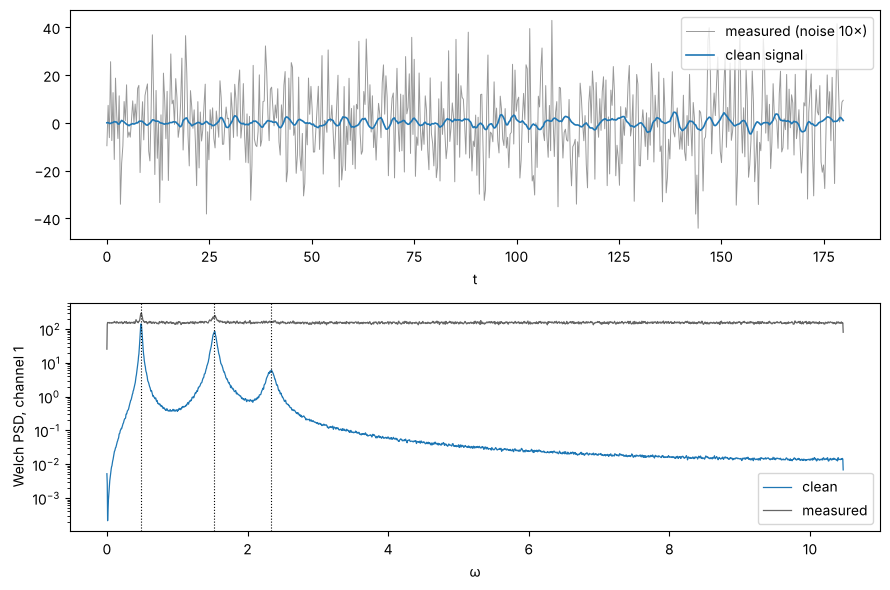

In [2]:
N = 1_000_000
y_clean = simulate(N, 0.0, 1)
y = simulate(N, 10.0, 1)            # same forces, plus measurement noise

fig, ax = plt.subplots(2, 1, figsize=(9, 6))
t = dt * np.arange(600)
ax[0].plot(t, y[:600, 0], color="0.6", lw=0.7, label="measured (noise 10×)")
ax[0].plot(t, y_clean[:600, 0], "C0", lw=1.2, label="clean signal")
ax[0].set_xlabel("t")
ax[0].legend(loc="upper right")
for yy, name, c in ((y_clean, "clean", "C0"), (y, "measured", "0.4")):
    f, P = welch(yy[:, 0], fs=1 / dt, nperseg=4096)
    ax[1].semilogy(2 * np.pi * f, P, color=c, lw=0.9, label=name)
for w in omega_true.real:
    ax[1].axvline(w, color="k", ls=":", lw=0.8)
ax[1].set_xlabel("ω")
ax[1].set_ylabel("Welch PSD, channel 1")
ax[1].legend()
fig.tight_layout()

The signal is invisible in the time trace. Even in the spectrum, averaged
over a million samples, the second and third resonances barely rise
above the flat noise floor: per resonance the signal-to-noise ratio is
even worse than the overall −20 dB, since most of the signal power is in
the first mode.

## 2. Why SSI can still work

White measurement noise $v_k$ is uncorrelated with itself at different
times and with the response. So it adds to the output correlation
$R_k = E[y_{m+k} y_m^T]$ **only at lag zero**. Covariance-driven SSI uses
$R_1, R_2, \dots$ only, so in expectation the noise drops out completely.
(Data-driven SSI achieves the same by projecting the future onto the
past: noise in the future is unpredictable from the past.)

What remains is the *estimation* error: the correlations are estimated
from a finite record, and the noise makes the estimates noisy.

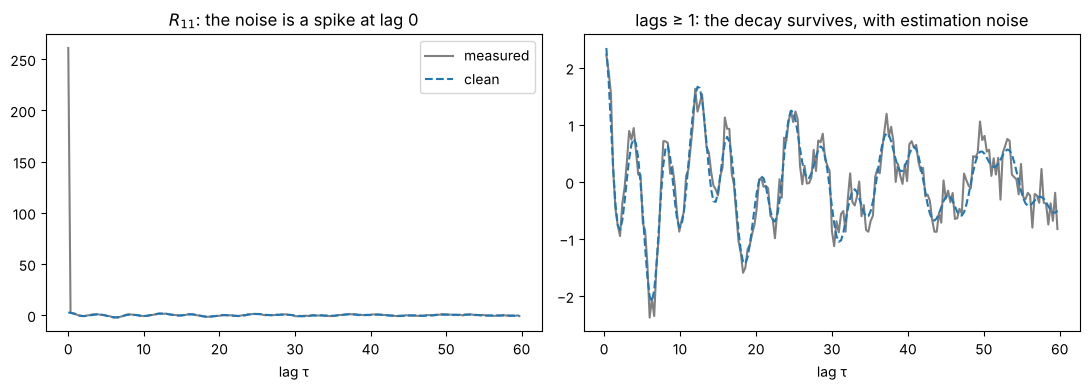

In [3]:
L = 200
lags = dt * np.arange(L)
R_clean = output_correlation(y_clean, L)
R = output_correlation(y, L)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(lags, R[:, 0, 0], color="0.5", label="measured")
ax[0].plot(lags, R_clean[:, 0, 0], "C0--", label="clean")
ax[0].set_title("$R_{11}$: the noise is a spike at lag 0")
ax[0].legend()
ax[1].plot(lags[1:], R[1:, 0, 0], color="0.5", label="measured")
ax[1].plot(lags[1:], R_clean[1:, 0, 0], "C0--", label="clean")
ax[1].set_title("lags ≥ 1: the decay survives, with estimation noise")
for a in ax:
    a.set_xlabel("lag τ")
fig.tight_layout()

The estimation noise of a correlation scales with the *total* variance of
the data, here dominated by the measurement noise: its standard deviation
is about $\sigma_y^2/\sqrt{N}$. Relative to the signal correlation, of
size $\sigma_s^2$, the error is therefore

$$\frac{\delta R}{R} \sim \frac{\sigma_s^2 + \sigma_n^2}{\sigma_s^2\sqrt{N}}
  \approx \Bigl(\frac{\sigma_n}{\sigma_s}\Bigr)^2 \frac{1}{\sqrt N}
  \quad\text{for } \sigma_n \gg \sigma_s.$$

This is the central scaling for very noisy data: in the worst case **ten
times more noise needs ten thousand times more samples** for the same
accuracy. Section 4 checks how the identified poles actually behave.

## 3. Identification at −20 dB

With a million samples (about 23 000 periods of the slowest mode) the
stabilization diagram still shows all three modes:

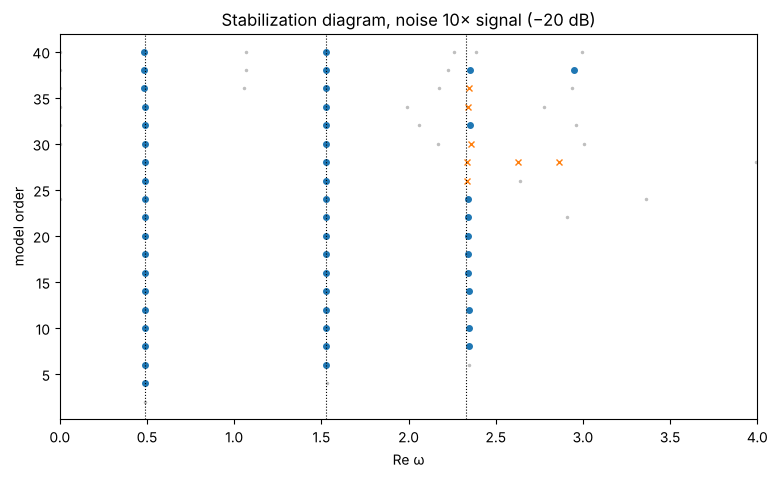

In [4]:
st = ssi_stabilization(y, dt, range(2, 41, 2), block_rows=40)
fig, ax = plt.subplots(figsize=(9, 5))
st.plot(ax)
for w in omega_true.real:
    ax.axvline(w, color="k", ls=":", lw=0.8)
ax.set_xlim(0, 4)
ax.set_title("Stabilization diagram, noise 10× signal (−20 dB)");

Surprisingly clean: all three modes are stable from low orders on, and
there are few noise poles, since white measurement noise has no structure
at lags ≥ 1 that the model could fit. Only the weakest mode starts to
wobble above order 25, where the extra states begin to fit estimation
noise next to it. A low order is the safe choice; the singular values
show why: six stand above a high, flat floor.

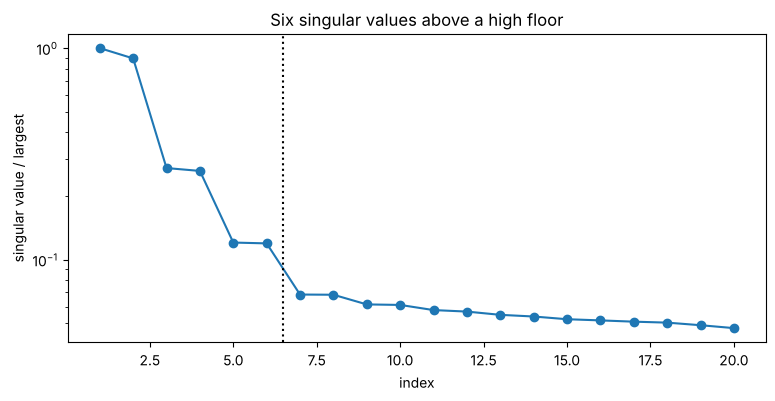

In [5]:
s = st.info["singular_values"]
plt.semilogy(np.arange(1, 21), s[:20] / s[0], "o-")
plt.axvline(6.5, color="k", ls=":")
plt.xlabel("index")
plt.ylabel("singular value / largest")
plt.title("Six singular values above a high floor");

In [6]:
for name, fn in (("SSI-Cov", ssi_cov), ("SSI-Data", ssi_data)):
    r = fn(y, dt, order=6, block_rows=40).select(max_damping=0.3)
    print(name)
    print(r)
    print("  frequency error / %:", 100 * (r.omega.real - omega_true.real) / omega_true.real)
    print("  damping error / %:  ", 100 * (r.damping_ratio - zeta_true) / zeta_true)
    print()

SSI-Cov
SSIResult with 3 modes, order 6, 3 channel(s), method cov
    omega.real     omega.imag       zeta         |d|     error
     0.4858526    -0.01384035    0.02848      0.9713   7.9e-06
      1.528941    -0.03707583    0.02424        1.53   5.9e-05
      2.345642    -0.07908158     0.0337      0.2298    0.0019
  frequency error / %: [-0.1589  0.1777  0.6758]
  damping error / %:   [12.0591 11.119  22.0915]



SSI-Data
SSIResult with 3 modes, order 6, 3 channel(s), method data
    omega.real     omega.imag       zeta         |d|     error
     0.4856951    -0.01390512    0.02862      0.9708     1e-05
      1.528549    -0.03819871    0.02498       1.551   4.2e-05
      2.347744    -0.07922091    0.03372      0.2438    0.0027
  frequency error / %: [-0.1913  0.1521  0.766 ]
  damping error / %:   [12.6195 14.5116 22.197 ]



Frequencies come out within a per cent, damping ratios within 10–20 %: the
damping ratio is always the most fragile quantity in operational modal
analysis, and noise makes it worse. Both SSI variants behave the same.

## 4. Error versus noise level

Eight realisations per noise level, 100 000 samples, three channels; the
plot shows the median relative error of the complex frequency,
$|\hat\omega - \omega|/|\omega|$, which combines frequency and damping.

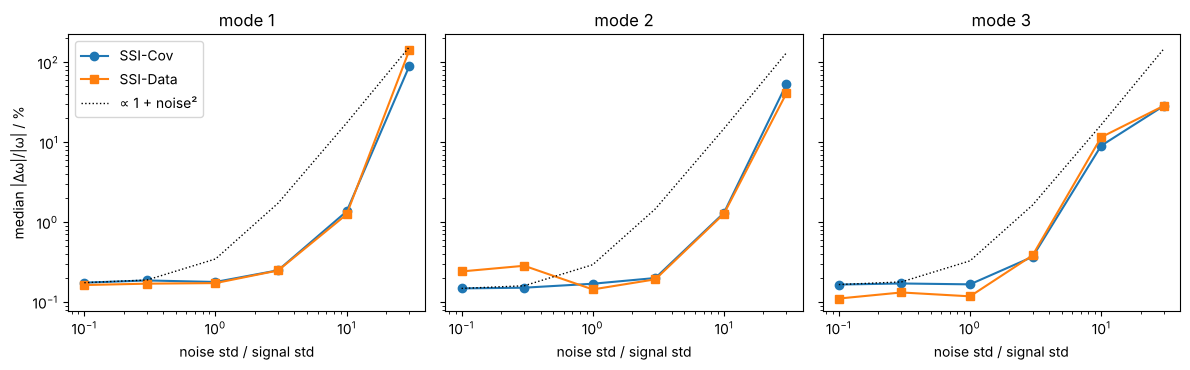

In [7]:
noise_levels = [0.1, 0.3, 1, 3, 10, 30]
reps = 8
N_mc = 100_000
med = {"SSI-Cov": [], "SSI-Data": []}
for noise in noise_levels:
    errs = {m: [] for m in med}
    for s in range(reps):
        yy = simulate(N_mc, noise, 100 + s)
        errs["SSI-Cov"].append(pole_errors(ssi_cov(yy, dt, order=12, block_rows=40).select(max_damping=0.3)))
        errs["SSI-Data"].append(pole_errors(ssi_data(yy, dt, order=12, block_rows=40).select(max_damping=0.3)))
    for m in med:
        med[m].append(np.median(errs[m], axis=0))
med = {m: np.array(v) for m, v in med.items()}

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
x = np.array(noise_levels)
for j, ax in enumerate(axs):
    for m, mk in zip(med, "os"):
        ax.loglog(x, 100 * med[m][:, j], mk + "-", label=m)
    ref = 100 * med["SSI-Cov"][0, j] / (1 + x[0] ** 2)
    ax.loglog(x, ref * (1 + x ** 2), "k:", lw=1, label="∝ 1 + noise²")
    ax.set_title(f"mode {j + 1}")
    ax.set_xlabel("noise std / signal std")
axs[0].set_ylabel("median |Δω|/|ω| / %")
axs[0].legend()
fig.tight_layout()

Up to a noise level of about 3 (−10 dB) the measurement noise hardly
matters: the error is set by the randomness of the excitation itself.
Then it rises steeply, more like a threshold than like the smooth
estimate $\propto 1 + (\sigma_n/\sigma_s)^2$ (dotted), which is too
pessimistic at moderate noise. The reason is the same as for the
detection limit of harmonic inversion: as long as a mode's singular
values stand clearly above the noise floor, the subspace and with it the
pole are barely disturbed; once the floor reaches them, the mode is lost
quickly. The weak third mode goes first. At 30× (−30 dB) 100 000 samples
are not enough for any mode: errors of tens of per cent mean that a noise
pole was picked instead.

SSI-Cov and SSI-Data are equally robust. SSI-Data is not better at
rejecting measurement noise, since both remove it in the same way.

## 5. What helps, and what hurts

**Longer records** are the main remedy, at the steep price derived
above: since the error scales as $(\sigma_n/\sigma_s)^2/\sqrt N$, going
from 3× to 10× noise can need up to $(10/3)^4 \approx 120$ times as much
data; section 3 used ten times the record length of section 4.

**Decimation** reduces the noise that falls into the band of the modes.
Here the sampling is 4.5 times faster than the highest mode needs. A
linear-phase low-pass filter and taking every third sample removes two
thirds of the noise power; the filtered noise is no longer quite white,
but its correlation is confined to a few lags near zero.

**Band-pass filtering** to the band of the modes, on the other hand,
*hurts*: it turns the white noise into a narrow-band process with a long
correlation time, so the noise now contributes to many lags of the
correlation function and the excitation filter's own poles compete with
the structural ones.

**More channels** average the noise and separate modes by shape. Using a
single channel shows the opposite effect.

In [8]:
variants = ["3 channels", "decimated by 3", "band-pass 0.3–2.7", "1 channel"]
noise = 10.0
reps = 6
errs = {v: [] for v in variants}
sos = butter(4, [0.3 * dt / np.pi, 2.7 * dt / np.pi], btype="band", output="sos")
for s in range(reps):
    yy = simulate(300_000, noise, 200 + s)
    errs["3 channels"].append(pole_errors(ssi_cov(yy, dt, order=12, block_rows=40).select(max_damping=0.3)))
    yd = decimate(yy, 3, ftype="fir", axis=0)
    errs["decimated by 3"].append(pole_errors(ssi_cov(yd, 3 * dt, order=12, block_rows=20).select(max_damping=0.3)))
    yb = sosfiltfilt(sos, yy, axis=0)
    errs["band-pass 0.3–2.7"].append(pole_errors(ssi_cov(yb, dt, order=12, block_rows=40).select(max_damping=0.3)))
    errs["1 channel"].append(pole_errors(ssi_cov(yy[:, 0], dt, order=12, block_rows=60).select(max_damping=0.3)))

print("noise 10×, 300 000 samples, median |Δω|/|ω| in % per mode")
for v in variants:
    print(f"  {v:20s}", np.round(100 * np.median(errs[v], axis=0), 2))

noise 10×, 300 000 samples, median |Δω|/|ω| in % per mode
  3 channels           [0.6  1.18 2.54]
  decimated by 3       [0.54 0.53 3.08]
  band-pass 0.3–2.7    [15.51 72.12 81.71]
  1 channel            [ 2.33  0.53 34.39]


Decimation halves the error of the second mode and leaves the others
about the same (the third mode lies close to the new Nyquist frequency,
where the anti-aliasing filter starts to act), and the identification
becomes cheaper. Band-pass filtering is a disaster, and a single channel
loses the mode that is weak in it.

## Summary

* White measurement noise does not bias SSI: it only enters the
  correlation at lag zero, which SSI-Cov ignores and SSI-Data projects
  away. It does inflate the statistical error.
* Up to a noise level of a few times the signal (−10 dB) measurement noise
  barely matters here. Beyond, the correlation estimates degrade like
  $(\sigma_n/\sigma_s)^2/\sqrt N$, and modes are lost quickly, weak ones
  first: in the worst case ten times more noise needs ten thousand times
  more data.
* At −20 dB a million samples of three channels still give all three modes,
  frequencies within a per cent, damping ratios within 10–20 %.
* Keep the model order low (two per expected mode plus little margin)
  and check it with a stabilization diagram.
* Decimate to comfortably above the highest mode of interest; use all channels;
  do **not** band-pass filter narrowly, since that colours the noise.
* SSI-Cov and SSI-Data are equally robust against measurement noise;
  SSI-Cov is much cheaper for the long records that noisy data need.